# HW1 - Tokenization and Word Vectors

Natural Language Processing (2026), Week 2: Tokenization

Part 1 implements BPE. Part 2 trains one Word2Vec model per tokenizer and
compares them. Part 3 is a short discussion grounded in those results.

Read `README.pdf` for the specification and the submission rules, and
`report_template.docx` for the questions. The code exists to produce the
evidence the questions ask for, so open the template before you start.

Pass `python test_bpe_public.py` before you submit.

In [1]:
import os, time, random, itertools #파일 경로나 cpu개수 딭렉터리 처리 등등
from collections import Counter #단어의 빈도를 계산하기 위함

import numpy as np #벡터 및 수치 계산
import matplotlib.pyplot as plt #그래프 생성

import bpe #내가 구현한거
import hw1_helpers as H #파일 처리 및 tokenizer학습 ,평가용 보조 함수

random.seed(0)
np.random.seed(0)

DATA_DIR = os.environ.get("HW1_DATA", "data")
TRAIN = os.path.join(DATA_DIR, "corpus_train.txt") #tokenizer와 word2vec 학습용
VALID = os.path.join(DATA_DIR, "corpus_valid.txt") #학습 결과 검증 및 token 수 측정
SMALL = os.path.join(DATA_DIR, "corpus_small.txt") #직접 구현한 bpe의 빠른 실험
os.makedirs("results", exist_ok=True)#결과 저장용 폴더
os.makedirs("artifacts", exist_ok=True)

SMOKE = "smoke" in DATA_DIR                     # 데이터 폴더 이름에 smoke가 들어가면 빠른 실험 실행 모드
VOCAB_SIZES = [500, 1000, 2000] if SMOKE else [2000, 8000, 32000] #왼쪽이 스모크 뒤에가 일반
W2V = dict(vector_size=100, window=5, negative=5, sg=1, seed=0, 
           min_count=1 if SMOKE else 5,
           epochs=2 if SMOKE else 5,
           workers=os.cpu_count() or 2)
#vector_size: 단어 벡터의 차원 수, window: 주변 단어를 고려하는 범위, negative: negative sampling 횟수, sg: skip-gram 모델 사용 여부,  min_count: 최소 단어 빈도수, epochs: 학습 반복 횟수, workers: 학습에 사용할 CPU 코어 수
print("data:", DATA_DIR, "| SMOKE =", SMOKE)
print("Word2Vec:", W2V)

data: data | SMOKE = False
Word2Vec: {'vector_size': 100, 'window': 5, 'negative': 5, 'sg': 1, 'seed': 0, 'min_count': 5, 'epochs': 5, 'workers': 10}


---
## Part 0. Corpus

Build the three slices and verify the checksums.

```
python prepare_corpus.py
```

In [2]:
rows = [] #결과를 담을 리스트인데 corpus의 퉁계를 딕셔너리 형태로 저장한 리스트
for name, path in [("train", TRAIN), ("valid", VALID), ("small", SMALL)]:#세개의 corpus를 순회
    s = H.corpus_stats(path) #통계 계산 줄수 문자수 공백 기준 단어 수 계산
    """s = {
    "lines": 175152,
    "chars": 106424973,
    "words": 19999973
    } """ #이런식으로 저장됌
    rows.append({"slice": name, **{k: s[k] for k in ("lines", "chars", "words")}})
H.save_table(rows, "results/00_corpus.csv")
for r in rows:
    print("%-6s lines=%8d  chars=%12d  words=%11d"
          % (r["slice"], r["lines"], r["chars"], r["words"]))

train  lines=  175152  chars=   106424973  words=   19999973
valid  lines=    4217  chars=     2644579  words=     499763
small  lines=    8126  chars=     4989679  words=     938931


---
## Part 1. BPE

Implement `bpe.py`, then run the cells below in order.


1-2  작은 예제로 BPE 원리 확인

1-3  직접 만든 BPE를 small corpus에서 학습

1-4  Hugging Face BPE와 비교

1-5  두 구현의 학습 시간 비교

1-6  vocabulary 크기가 다른 BPE 세 개 학습

### 1-2. Reproduce the lecture example
작은 예저로 bpe원리 확인

Slides 15-21. The merges are `u+g` (20), `u+n` (16), `h+ug` (15), and the
vocabulary grows `{b,g,h,n,p,s,u}` to `+ug` to `+un` to `+hug`.

In [3]:
TOY = {"hug": 10, "pug": 5, "pun": 12, "bun": 4, "hugs": 5}

merges_toy = bpe.train_bpe(TOY, 3)
print("merges:", merges_toy)
assert merges_toy == [("u", "g"), ("u", "n"), ("h", "ug")]

for k in range(4):  #vocabulary 증가 확인 k=3이면 3번 병합
    v = bpe.build_vocab(TOY, bpe.train_bpe(TOY, k)) 
    print("k=%d  V = {%s}" % (k, ", ".join(t for t in v if t not in bpe.SPECIALS)))#스페셜 토큰 제외

vocab_toy = bpe.build_vocab(TOY, merges_toy)
print("segmentation:", bpe.tokenize("hug pug pun bun hugs", merges_toy, vocab_toy))

merges: [('u', 'g'), ('u', 'n'), ('h', 'ug')]
k=0  V = {b, g, h, n, p, s, u}
k=1  V = {b, g, h, n, p, s, u, ug}
k=2  V = {b, g, h, n, p, s, u, ug, un}
k=3  V = {b, g, h, n, p, s, u, ug, un, hug}
segmentation: [['hug'], ['p', 'ug'], ['p', 'un'], ['b', 'un'], ['hug', 's']]


### 1-3. Train on the small slice

Learn 1,000 merges on the 5 MB slice and print the first 50 merge rules in order.

In [4]:
lines_small = H.read_lines(SMALL) # corpus_small.txt를 줄 단위로 읽음
wf_small = bpe.count_words(lines_small) #단어별 빈도표를 만든다.
print("word types:", len(wf_small))

NUM_MERGES = 200 if SMOKE else 1000 # data_smoke  라면 200 번 실제 데이터면 1000번

start_time = time.perf_counter() # BPE학습 시간 기록
merges_mine = bpe.train_bpe(wf_small, NUM_MERGES) #corpus에서 merge 규칙 1000개를 학습한다. 시험에 나올것 같음
time_mine = time.perf_counter() - start_time #학습이 끝난 시간에서 시작시간 뺴기
vocab_mine = bpe.build_vocab(wf_small,merges_mine)#기본문자와 학습된 merge token을 이용해 vocabulary를 만든다. 이것도
for rank,pair in enumerate(merges_mine[:50],start=1):
    print(rank, pair)


word types: 49398
1 ('t', 'h')
2 ('i', 'n')
3 ('th', 'e')
4 ('a', 'n')
5 ('e', 'r')
6 ('o', 'n')
7 ('e', 'd')
8 ('r', 'e')
9 ('a', 't')
10 ('o', 'r')
11 ('e', 'n')
12 ('a', 'l')
13 ('s', 't')
14 ('a', 'r')
15 ('o', 'f')
16 ('an', 'd')
17 ('a', 's')
18 ('in', 'g')
19 ('e', 's')
20 ('i', 's')
21 ('i', 't')
22 ('t', 'o')
23 ('o', 'u')
24 ('i', 'c')
25 ('h', 'e')
26 ('i', 'on')
27 ('l', 'e')
28 ('r', 'o')
29 ('c', 'h')
30 ('i', 'l')
31 ('en', 't')
32 ('a', 'd')
33 ('s', 'e')
34 ('a', 'm')
35 ('o', 'm')
36 ('b', 'e')
37 ('a', 'c')
38 ('l', 'y')
39 ('w', 'as')
40 ('f', 'or')
41 ('u', 'r')
42 ('d', 'e')
43 ('v', 'e')
44 ('o', 'l')
45 ('T', 'he')
46 ('i', 'r')
47 ('i', 'm')
48 ('-', '@')
49 ('@', '-@')
50 ('o', 'w')


The merge list is the evidence for **question 1-3** of the report.

### 1-4. Compare against the library

Train `tokenizers` on the same corpus at the same vocabulary size.
Measure the vocabulary Jaccard similarity and the token count on the same text.

이번엔 허깅 페이스의 tokenizers라이브러리로 BPE를 학습 하는것

In [5]:
# TODO: train a library tokenizer at the same vocabulary size with H.train_hf_bpe.
# TODO: compute the vocabulary Jaccard similarity.
# TODO: count the tokens both implementations produce on the same sample lines.
# TODO: segment the probe sentence with both and print them side by side.
hf_small,time_hf = H.train_hf_bpe(SMALL, vocab_size= len(vocab_mine),save_path="artifacts/bpe_small.json")
# 두 vocabulary의 Jaccard similarity를 계산한다. 두 vocabulary의 교집합을 구하고 합집합을 구한 후 교집합 크기를 합집합 크기로 나눈다.
#그니까 내가 실제로 구현한얘랑 HuggingFace에서 제공하는 tokenizer랑 비교하는거임
mine_vocab_set = set(vocab_mine)
hf_vocab_set = set(hf_small.get_vocab().keys())


intersection = mine_vocab_set & hf_vocab_set #교집합
union = mine_vocab_set | hf_vocab_set #합집합

jaccard_similarity = len(intersection) / len(union)

print("mine vocabulary size:", len(mine_vocab_set))
print("HF vocabulary size:", len(hf_vocab_set))
print("Jaccard similarity:", jaccard_similarity)

# 동일한 200개 문장으로 token 개수를 비교한다.
sample_lines = lines_small[:200]  # small corpus에서 처음 200줄을 샘플로 사용

mine_token_count = sum(
    len(bpe.encode(line, merges_mine, vocab_mine))
    for line in sample_lines
)# 각문장을 encode한 뒤에 갯수를 더함  내가 만든 bpe

hf_token_count = sum(
    len(hf_small.encode(line).ids)
    for line in sample_lines
) #허깅 페이스에서 제공하는 encode를 이용해서 토큰화한 뒤에 갯수를 더함

print("mine token count:", mine_token_count)
print("HF token count:", hf_token_count)

# 두 tokenizer가 같은 문장을 어떻게 나누는지 비교한다.
probe = "The unbelievable tokenization of 2026 costs $3.50."

mine_segmentation = bpe.tokenize(
    probe,
    merges_mine,
    vocab_mine,
)

hf_segmentation = hf_small.encode(probe).tokens

print("mine:", mine_segmentation)
print("HF:", hf_segmentation)


mine vocabulary size: 1612
HF vocabulary size: 1612
Jaccard similarity: 0.21522804372408594
mine token count: 43777
HF token count: 28596
mine: [['The'], ['un', 'be', 'li', 'ev', 'able'], ['to', 'k', 'en', 'iz', 'ation'], ['of'], ['20', '2', '6'], ['co', 'st', 's'], ['$', '3', '.', '50', '.']]
HF: ['ĠThe', 'Ġun', 'b', 'el', 'ie', 'v', 'able', 'Ġto', 'k', 'en', 'iz', 'ation', 'Ġof', 'Ġ20', '2', '6', 'Ġc', 'ost', 's', 'Ġ$', '3', '.', '5', '0', '.']


The Jaccard similarity, the token counts and the two segmentations of the
probe sentence are the evidence for **question 1-4** of the report.

### 1-5. Training time

In [7]:
rows = [
    {"impl": "mine (pure python)", "merges": len(merges_mine),
     "vocab": len(vocab_mine), "train_sec": round(time_mine, 2)},
    {"impl": "tokenizers (rust)", "merges": "-",
     "vocab": hf_small.get_vocab_size(), "train_sec": round(time_hf, 2)},
]
H.save_table(rows, "results/15_impl_time.csv") # 3두개의 학습 시간과 vocabulary 크기를 비교한 결과를 csv로 저장
for r in rows:
    print(r)

{'impl': 'mine (pure python)', 'merges': 1000, 'vocab': 1612, 'train_sec': 2.65}
{'impl': 'tokenizers (rust)', 'merges': '-', 'vocab': 1612, 'train_sec': 0.57}


### 1-6. Vocabulary sizes

Train three vocabulary sizes on the main corpus with `tokenizers`.
Part 2 reuses these tokenizers.

In [8]:
tok_table = []  #비교 결과를 행 단위로 저장할 리스트
tokenizers_by_k = {} # 학습한 tokenizer 객체 보관
for k in VOCAB_SIZES: #단어 크기별 반복 차례대로 2000,8000,32000
    # TODO: train vocabulary size k with H.train_hf_bpe and save to artifacts/bpe_<k>.json.
    # TODO: count the tokens on the validation slice with H.count_tokens.
    # TODO: append {tokenizer, vocab, valid_tokens, train_sec} to tok_table.
    name = f"bpe-{k // 1000}k" if k >= 1000 else f"bpe-{k}"

    # vocabulary 크기가 k인 BPE tokenizer를 학습하고 저장한다.
    tokenizer, train_sec = H.train_hf_bpe(
        TRAIN,
        vocab_size=k,
        save_path=f"artifacts/bpe_{k}.json", #각 tokenizer는 파일로 저장됌
    )

    # Part 2에서 다시 사용할 수 있도록 저장한다.
    tokenizers_by_k[k] = tokenizer #tokenizer 객체 보관

    # 검증 corpus를 tokenize했을 때 만들어지는 token 수를 센다.
    valid_token_count = H.count_tokens(tokenizer, VALID)

    # 결과 표에 한 행을 추가한다.
    tok_table.append({
        "tokenizer": name,
        "vocab": tokenizer.get_vocab_size(),
        "valid_tokens": valid_token_count,
        "train_sec": round(train_sec, 2),
    })


# Word-level baseline의 vocabulary를 구한다.
word_vocab = set()

# H.Wordsentences(TRAIN)는 TRAIN corpus를 문장 단위로 읽고 각 문장을 단어 단위로 나눈다.
for words in H.WordSentences(TRAIN):
    word_vocab.update(words)

# Word-level은 공백으로 단어를 나누므로 검증 corpus의 단어 수가 token 수다.
word_valid_tokens = H.corpus_stats(VALID)["words"]

tok_table.append({
    "tokenizer": "word-level",
    "vocab": len(word_vocab),
    "valid_tokens": word_valid_tokens,
    "train_sec": 0.0,
})


H.save_table(tok_table, "results/16_tokenizers.csv") #테이블 형태로 저장

for row in tok_table:
    print(row)

{'tokenizer': 'bpe-2k', 'vocab': 2000, 'valid_tokens': 869758, 'train_sec': 5.16}
{'tokenizer': 'bpe-8k', 'vocab': 8000, 'valid_tokens': 658717, 'train_sec': 5.41}
{'tokenizer': 'bpe-32k', 'vocab': 32000, 'valid_tokens': 557985, 'train_sec': 6.23}
{'tokenizer': 'word-level', 'vocab': 259319, 'valid_tokens': 499763, 'train_sec': 0.0}


---
## Part 2. Word2Vec

### 2-1. The limit of one-hot vectors (slides 27-29)

Compute the cosine similarity between the one-hot vectors of two distinct words.

In [9]:
# TODO: take the 20,000 most frequent words of the validation slice and print |V|.
# TODO: show that the cosine similarity of two distinct one-hot vectors is always 0.

valid_word_counter = Counter()

for words in H.WordSentences(VALID): #validation corpus를 문장 단위로 읽고 각 문장을 단어 단위로 나눈다.
    valid_word_counter.update(words) #단어의 출현 횟수를 누적함

# Take the 20,000 most frequent words
onehot_vocab = [word for word, _ in valid_word_counter.most_common(20000)]
print("|V| (20,000 most frequent words):", len(onehot_vocab))
# 여기서 |V|는 vocabulary의 크기를 의미함

word_a= onehot_vocab[0]
word_b= onehot_vocab[1] 

onehot_a =np.zeros(len(onehot_vocab))
onehot_b =np.zeros(len(onehot_vocab))
#크기가 |V|인 0으로 채워진 벡터를 만든다. one-hot encoding을 위해서
onehot_a[0] = 1
onehot_b[1] = 1
#서로다른 위치에 1을 넣어 one-hot vector를 만든다. word_a는 0번째, word_b는 1번째에 1을 넣음
cosine_similarity = np.dot(onehot_a, onehot_b) / (np.linalg.norm(onehot_a) * np.linalg.norm(onehot_b))

print("word A:", word_a)
print("word B:", word_b)
print("dot product:", np.dot(onehot_a, onehot_b))
print("Cosine Similarity:", cosine_similarity)


|V| (20,000 most frequent words): 20000
word A: the
word B: ,
dot product: 0.0
Cosine Similarity: 0.0


### 2-2 / 2-3. Train four models

Train `word-level`, `bpe-2k`, `bpe-8k`, and `bpe-32k` under one setting.

In [10]:
from gensim.models import Word2Vec

models = {}
train_times = {}
# TODO: train the word-level model from H.WordSentences.
# TODO: train one model per BPE tokenizer from H.BpeSentences.
# TODO: print the training time and vocabulary size of each.
# word-level word2vec 모델 학습
name = "word-level"
sentences = list(H.WordSentences(TRAIN))

start_time = time.perf_counter()
model = Word2Vec(sentences, **W2V)
end_time = time.perf_counter()
train_times[name] = end_time - start_time
models[name] = model

print("%-12s trian_sec=%.2f  |V|=%d" % (name, train_times[name], len(model.wv)))

# 각 BPE tokenizer로 Word2Vec 모델을 학습한다.
for k in VOCAB_SIZES:
    name = f"bpe-{k // 1000}k" if k >= 1000 else f"bpe-{k}"
    tokenizer = tokenizers_by_k[k]
    sentences = list(H.BpeSentences(TRAIN, tokenizer))

    start_time = time.perf_counter()
    model = Word2Vec(sentences, **W2V)
    end_time = time.perf_counter()
    train_times[name] = end_time - start_time
    models[name] = model

    print("%-12s trian_sec=%.2f  |V|=%d" % (name, train_times[name], len(model.wv)))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

word-level   trian_sec=54.53  |V|=85403


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

bpe-2k       trian_sec=91.58  |V|=1923


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

bpe-8k       trian_sec=66.12  |V|=7881


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

bpe-32k      trian_sec=56.36  |V|=31123


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


### 2-4. Evaluation

Report nearest neighbours, analogy accuracy, the WordSim-353 correlation, and
coverage of the evaluation vocabulary. `questions-words.txt` and
`wordsim353.tsv` ship with gensim.

An analogy question searches the whole vocabulary for the nearest word, so a
small vocabulary has an advantage. Evaluate all four models over one shared
candidate set, `CANDIDATES`.

In [22]:
PROBE = ["city", "king", "water", "music", "government",
         "computer", "river", "school", "money", "war"]

for name, m in models.items(): #학습한 모델을 하나씩 순회함
    print("=" * 60)
    print(name)
    for w in PROBE[:5]:
        if w in m.wv.key_to_index: #해당 단어가 모델 vocabulary에 있는지 확인
            nn = ", ".join(x for x, _ in m.wv.most_similar(w, topn=5)) #있으면 가장 가까운 token 5개를 가지고와서 합침
            print("  %-12s -> %s" % (w, nn))
        else:
            print("  %-12s -> (not in vocabulary)" % w) #없으면 없다고 한다. 

word-level
  city         -> town, municipality, Jahanpanah, township, Antananarivo
  king         -> emperor, prince, kings, Æthelwulf, duke
  water        -> groundwater, potable, silt, permafrost, aquifer
  music        -> reggae, DJs, bolero, musical, boleros
  government   -> Government, governments, administration, bureaucracy, authorities
bpe-2k
  city         -> (not in vocabulary)
  king         -> (not in vocabulary)
  water        -> (not in vocabulary)
  music        -> (not in vocabulary)
  government   -> (not in vocabulary)
bpe-8k
  city         -> (not in vocabulary)
  king         -> (not in vocabulary)
  water        -> Ġwater, ground, inking, Ġsea, Ġground
  music        -> (not in vocabulary)
  government   -> (not in vocabulary)
bpe-32k
  city         -> Ġcommuter, Ġplazas, Ġterminal, Ġvehic, Ġseasonal
  king         -> Ġtrek, winter, aking, umbling, emen
  water        -> waters, ĠBridg, banks, Ġdams, Ġcreek
  music        -> ĠPitchfork, ĠPopMatters, ĠVibe, ĠSlant

In [29]:
eval_words = H.analogy_words() | H.wordsim_words() # coverage 평가, 평가 에 필요한 단어 중 모델 vocabulary가 직접 가지고 있는 단어의 비율
N_CAND = 5000 if SMOKE else 50000
# TODO: build CANDIDATES with H.top_words: the top N_CAND words plus the evaluation words.
# TODO: for each model, measure coverage of the evaluation words with H.coverage
#       and collect the results in raw_rows.
CANDIDATES = set(H.top_words(VALID, N_CAND)) | eval_words #모든 모델이 사용할 공통 후보 단어 집합
# train corpus에서 자주 등장한 단어 50000개와 평가 문제에 등장하는 모든 단어

raw_rows =[] #원래 vodabulary 의 평가 단어 coverage

for model_name, model in models.items():
    raw_coverage = H.coverage(model.wv.key_to_index, eval_words) #모델 vocabulary에 직접 존재하는 평가 단어 수/전체 평가 단어수
    raw_rows.append({"model": model_name, "coverage": raw_coverage})
    print("%-12s coverage=%.4f" % (model_name, raw_coverage))
print("eval_words:", len(eval_words), "candidates:", len(CANDIDATES))

word-level   coverage=0.9530
bpe-2k       coverage=0.0121
bpe-8k       coverage=0.0288
bpe-32k      coverage=0.0895
eval_words: 1319 candidates: 9834


The coverage column is the evidence for **question 2-4** of the report.

### 2-5. Word vectors from subwords

The BPE vocabulary holds subwords, so most evaluation words are absent.
Build a word vector as the **mean** of its subword vectors. Restrict the
word-level model to the same candidate set and evaluate all four together.

In [32]:
comp_rows = []
sections = {}    # model name -> {section: (correct, total)}
# TODO: restrict the word-level model to CANDIDATES with H.restrict_kv.
# TODO: build word vectors for the BPE models with H.subword_word_vectors.
# TODO: score all four with H.coverage and H.evaluate and collect them in comp_rows.

# word -level 모델을 CANDIDATES로 제한/ H.restrict_kv의 반환값 평가용 단어 벡터와 후보 단어 수
word_eval_kv, word_candidate_count = H.restrict_kv(models["word-level"].wv, CANDIDATES)

#Coverage,analogy,WordSim을 평가
word_scores = H.evaluate(word_eval_kv)

#다음 셀의 section별 평가를 위해 저장함
sections["word-level"]= word_scores.get("analogy_sections",{},)
word_row={"model": "word-level",
          "eval_kind": "native-word",
          "vocab": len(models["word-level"].wv),
          "coverage": H.coverage(word_eval_kv.key_to_index, eval_words),
          "analogy_acc": word_scores.get("analogy_acc", float("nan")), #man : king = woman : queen
          "wordsim_spearman": word_scores.get("wordsim_spearman", float("nan")), #사람이 판단한 단어 유사도와 모델의 단어 유사도 간의 상관계수
          }
comp_rows.append(word_row)

print("word-level:", "model vocab:", len(models["word-level"].wv), "candidate_count:", word_candidate_count, "coverage:", word_row["coverage"], "analogy_acc:", word_row["analogy_acc"], "wordsim_spearman:", word_row["wordsim_spearman"])



#bpe 모델 평가
for k in VOCAB_SIZES:
    name = f"bpe-{k // 1000}k" if k >= 1000 else f"bpe-{k}"
    #subword word vector의 평균으로 단어 백터를 만든다.
    bpe_eval_kv,built_count = H.subword_word_vectors(models[name].wv, tokenizers_by_k[k], CANDIDATES)

    
    # Coverage, Analogy, WordSim 평가
    bpe_scores = H.evaluate(bpe_eval_kv)

    # 다음 셀의 section별 평가를 위해 저장함
    sections[name] = bpe_scores.get("analogy_sections", {})

    bpe_row = {
        "model": name,
        "eval_kind": "subword-mean",
        "vocab": len(models[name].wv),
        "coverage": H.coverage(bpe_eval_kv.key_to_index, eval_words),
        "analogy_acc": bpe_scores.get("analogy_acc", float("nan")),
        "wordsim_spearman": bpe_scores.get("wordsim_spearman", float("nan")),
    }
    comp_rows.append(bpe_row)

    print(f"{name}: model vocab: {len(models[name].wv)}, candidate_count: {built_count}, coverage: {bpe_row['coverage']}, analogy_acc: {bpe_row['analogy_acc']}, wordsim_spearman: {bpe_row['wordsim_spearman']}")



H.save_table(comp_rows, "results/25_word_level_eval.csv")


print()
for row in comp_rows:
    print(row)

word-level: model vocab: 85403 candidate_count: 9464 coverage: 0.9529946929492039 analogy_acc: 0.2563336445689387 wordsim_spearman: 0.48888940562375277
bpe-2k: model vocab: 1923, candidate_count: 9834, coverage: 1.0, analogy_acc: 0.2385898485468686, wordsim_spearman: 0.189777803903997
bpe-8k: model vocab: 7881, candidate_count: 9834, coverage: 1.0, analogy_acc: 0.19591690544412607, wordsim_spearman: 0.2704767174370196
bpe-32k: model vocab: 31123, candidate_count: 9834, coverage: 1.0, analogy_acc: 0.21449038067949242, wordsim_spearman: 0.43068316193370676

{'model': 'word-level', 'eval_kind': 'native-word', 'vocab': 85403, 'coverage': 0.9529946929492039, 'analogy_acc': 0.2563336445689387, 'wordsim_spearman': np.float64(0.48888940562375277)}
{'model': 'bpe-2k', 'eval_kind': 'subword-mean', 'vocab': 1923, 'coverage': 1.0, 'analogy_acc': 0.2385898485468686, 'wordsim_spearman': np.float64(0.189777803903997)}
{'model': 'bpe-8k', 'eval_kind': 'subword-mean', 'vocab': 7881, 'coverage': 1.0, 'a

### 2-5b. Analogy accuracy by section

`questions-words.txt` has 14 sections. The first five (capitals, currency,
city-in-state, family) test meaning. `gram1` through `gram9` test form:
adjective to adverb, comparative, superlative, present participle, past tense,
plural.

Print the accuracy of each section together with the **number of scored
questions**. A question containing a word outside the vocabulary is skipped,
so the count differs across models.

These tables are the evidence for **question 3-1** of the report.

In [25]:
# TODO: print per-section accuracy from sections, marking meaning and form sections.
# TODO: for each model compute semantic accuracy, syntactic accuracy, and the number
#       of scored questions, and save them to results/25b_sections.csv.

semantic_sections = {"capital-common-countries", "capital-world", "currency", "city-in-state", "family"}
section_rows = []
for model_name, model_sections in sections.items():
    print("=" * 60)
    print(model_name)
    semantic_correct = 0
    semantic_total = 0
    syntactic_correct = 0
    syntactic_total = 0

    for section_name, (correct, total) in model_sections.items():

        if  section_name == "Total accuracy":
            continue
        if section_name in semantic_sections:
            group = "meaning"
            semantic_correct += correct
            semantic_total += total
        elif section_name.startswith("gram"):
            group = "form"
            syntactic_correct += correct
            syntactic_total += total
        else:
            group = "other"

        accuracy = correct / total if total > 0 else float("nan")
        print( f"[{group}] {section_name:32s} " f"accuracy={accuracy:.4f}  ({correct}/{total})")

    semantic_accuracy = semantic_correct / semantic_total if semantic_total > 0 else float("nan")
    syntactic_accuracy = syntactic_correct / syntactic_total if syntactic_total > 0 else float("nan")

    section_rows.append({
            "model": model_name,
            "group": "meaning",
            "correct": semantic_correct,
            "scored": semantic_total,
            "accuracy": semantic_accuracy,
        })

    section_rows.append({
            "model": model_name,
            "group": "form",
            "correct": syntactic_correct,
            "scored": syntactic_total,
            "accuracy": syntactic_accuracy,
        })

    print("-" * 70)
    print(
        "meaning : accuracy=%7.4f  scored=%5d  correct=%5d"
        % (
            semantic_accuracy,
            semantic_total,
            semantic_correct,
         )
    )
    print(
         "form: accuracy=%7.4f  scored=%5d  correct=%5d"
        % (
            syntactic_accuracy,
            syntactic_total,
            syntactic_correct,
            )
    )


H.save_table(
    section_rows,
    "results/25b_sections.csv",
    )

word-level
[meaning] capital-common-countries         accuracy=0.4130  (209/506)
[meaning] capital-world                    accuracy=0.1985  (515/2595)
[meaning] currency                         accuracy=0.0926  (10/108)
[meaning] city-in-state                    accuracy=0.1756  (422/2403)
[meaning] family                           accuracy=0.3079  (117/380)
[form] gram1-adjective-to-adverb        accuracy=0.1065  (99/930)
[form] gram2-opposite                   accuracy=0.1825  (138/756)
[form] gram3-comparative                accuracy=0.2065  (275/1332)
[form] gram4-superlative                accuracy=0.0994  (105/1056)
[form] gram5-present-participle         accuracy=0.2198  (218/992)
[form] gram6-nationality-adjective      accuracy=0.5626  (813/1445)
[form] gram7-past-tense                 accuracy=0.4705  (734/1560)
[form] gram8-plural                     accuracy=0.2092  (249/1190)
[form] gram9-plural-verbs               accuracy=0.2635  (214/812)
-------------------------------

'results/25b_sections.csv'

### 2-6. Combined table

Put vocabulary size, validation token count, coverage, analogy accuracy,
correlation, and training time in one table.

This table answers **question 2-6** and is cited throughout Part 3.

In [33]:
valid_tokens = {r["tokenizer"]: r["valid_tokens"] for r in tok_table}
raw_cov = {r["model"]: r["coverage"] for r in raw_rows}

summary = []
for r in comp_rows:
    summary.append({
        "model": r["model"],
        "eval_kind": r["eval_kind"],
        "vocab": r["vocab"],
        "valid_tokens": valid_tokens.get(r["model"]),
        "raw_coverage": raw_cov.get(r["model"]),
        "coverage": r["coverage"],
        "analogy_acc": r["analogy_acc"],
        "wordsim_spearman": r["wordsim_spearman"],
        "train_sec": round(train_times.get(r["model"], float("nan")), 1),
    })
H.save_table(summary, "results/26_summary.csv")
for s in summary:
    print(s)

{'model': 'word-level', 'eval_kind': 'native-word', 'vocab': 85403, 'valid_tokens': 499763, 'raw_coverage': 0.9529946929492039, 'coverage': 0.9529946929492039, 'analogy_acc': 0.2563336445689387, 'wordsim_spearman': np.float64(0.48888940562375277), 'train_sec': 54.5}
{'model': 'bpe-2k', 'eval_kind': 'subword-mean', 'vocab': 1923, 'valid_tokens': 869758, 'raw_coverage': 0.012130401819560273, 'coverage': 1.0, 'analogy_acc': 0.2385898485468686, 'wordsim_spearman': np.float64(0.189777803903997), 'train_sec': 91.6}
{'model': 'bpe-8k', 'eval_kind': 'subword-mean', 'vocab': 7881, 'valid_tokens': 658717, 'raw_coverage': 0.02880970432145565, 'coverage': 1.0, 'analogy_acc': 0.19591690544412607, 'wordsim_spearman': np.float64(0.2704767174370196), 'train_sec': 66.1}
{'model': 'bpe-32k', 'eval_kind': 'subword-mean', 'vocab': 31123, 'valid_tokens': 557985, 'raw_coverage': 0.08946171341925702, 'coverage': 1.0, 'analogy_acc': 0.21449038067949242, 'wordsim_spearman': np.float64(0.43068316193370676), 'tr

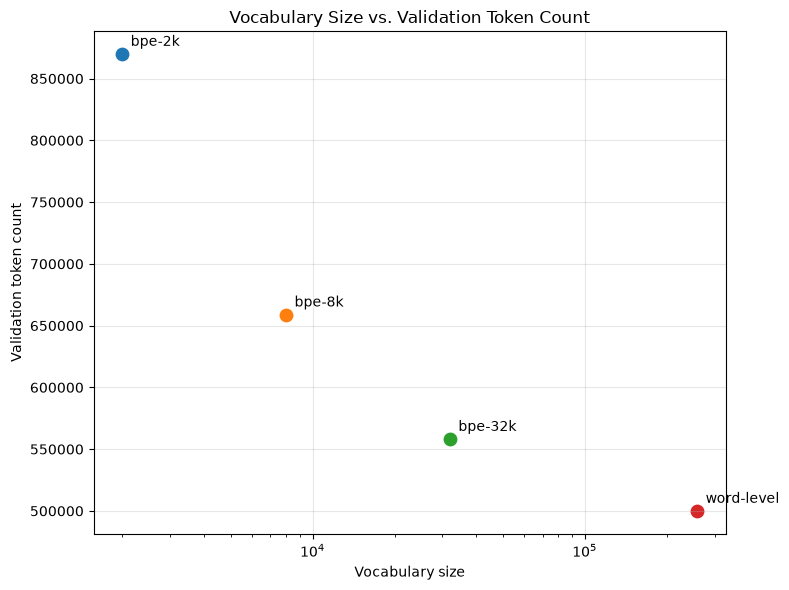

In [27]:
# TODO: scatter vocabulary size against the validation token count
#       and save it to results/26_vocab_vs_tokens.png.
plt.figure(figsize=(8, 6))

for row in tok_table:
    x = row["vocab"]
    y = row["valid_tokens"]
    name = row["tokenizer"]

    plt.scatter(
        x,
        y,
        s=80,
    )

    plt.annotate(
        name,
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
    )

# Vocabulary 크기의 범위가 매우 크므로 로그 축을 사용한다.
plt.xscale("log")

plt.xlabel("Vocabulary size")
plt.ylabel("Validation token count")
plt.title("Vocabulary Size vs. Validation Token Count")

plt.grid(
    True,
    alpha=0.3,
)

plt.tight_layout()

plt.savefig(
    "results/26_vocab_vs_tokens.png",
    dpi=150,
)

plt.show()

### 2-7. Hyper-parameter sweep

Retrain one model at three values of `window` or `vector_size`.
The resulting table answers **question 2-7**.

In [34]:
sweep_rows = []

WINDOW_VALUES = [2, 5, 10]

semantic_names = {
    "capital-common-countries",
    "capital-world",
    "currency",
    "city-in-state",
    "family",
}

for window_size in WINDOW_VALUES:
    print("=" * 70)
    print("Training word-level model with window =", window_size)

    # 기존 설정을 복사한 후 window만 변경한다.
    sweep_config = W2V.copy()
    sweep_config["window"] = window_size

    start_time = time.perf_counter()

    sweep_model = Word2Vec(
        sentences=H.WordSentences(TRAIN),
        **sweep_config,
    )

    elapsed = time.perf_counter() - start_time

    # 모든 실험에서 동일한 후보 단어 집합을 사용한다.
    eval_kv, candidate_count = H.restrict_kv(
        sweep_model.wv,
        CANDIDATES,
    )

    scores = H.evaluate(eval_kv)
    analogy_sections = scores.get("analogy_sections", {})

    # Semantic analogy 결과 합산
    semantic_correct = 0
    semantic_total = 0

    # Syntactic analogy 결과 합산
    syntactic_correct = 0
    syntactic_total = 0

    for section_name, (correct, total) in analogy_sections.items():
        if section_name in semantic_names:
            semantic_correct += correct
            semantic_total += total

        elif section_name.startswith("gram"):
            syntactic_correct += correct
            syntactic_total += total

    semantic_accuracy = (
        semantic_correct / semantic_total
        if semantic_total > 0
        else float("nan")
    )

    syntactic_accuracy = (
        syntactic_correct / syntactic_total
        if syntactic_total > 0
        else float("nan")
    )

    row = {
        "model": "word-level",
        "sweep_parameter": "window",
        "window": window_size,
        "vector_size": sweep_config["vector_size"],
        "vocab": len(sweep_model.wv),
        "candidate_vectors": candidate_count,
        "coverage": H.coverage(
            eval_kv.key_to_index,
            eval_words,
        ),
        "analogy_acc": scores.get(
            "analogy_acc",
            float("nan"),
        ),
        "semantic_acc": semantic_accuracy,
        "semantic_scored": semantic_total,
        "syntactic_acc": syntactic_accuracy,
        "syntactic_scored": syntactic_total,
        "wordsim_spearman": scores.get(
            "wordsim_spearman",
            float("nan"),
        ),
        "train_sec": round(elapsed, 2),
    }

    sweep_rows.append(row)
    print(row)


H.save_table(
    sweep_rows,
    "results/27_sweep.csv",
)

Training word-level model with window = 2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

{'model': 'word-level', 'sweep_parameter': 'window', 'window': 2, 'vector_size': 100, 'vocab': 85403, 'candidate_vectors': 9464, 'coverage': 0.9529946929492039, 'analogy_acc': 0.19433551198257082, 'semantic_acc': 0.13584779706275033, 'semantic_scored': 5992, 'syntactic_acc': 0.22912737019755783, 'syntactic_scored': 10073, 'wordsim_spearman': np.float64(0.39287477441064234), 'train_sec': 35.71}
Training word-level model with window = 5


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

{'model': 'word-level', 'sweep_parameter': 'window', 'window': 5, 'vector_size': 100, 'vocab': 85403, 'candidate_vectors': 9464, 'coverage': 0.9529946929492039, 'analogy_acc': 0.2529100529100529, 'semantic_acc': 0.21011348464619492, 'semantic_scored': 5992, 'syntactic_acc': 0.2783679142261491, 'syntactic_scored': 10073, 'wordsim_spearman': np.float64(0.47456251858500703), 'train_sec': 57.23}
Training word-level model with window = 10


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

{'model': 'word-level', 'sweep_parameter': 'window', 'window': 10, 'vector_size': 100, 'vocab': 85403, 'candidate_vectors': 9464, 'coverage': 0.9529946929492039, 'analogy_acc': 0.27606598194833487, 'semantic_acc': 0.25116822429906543, 'semantic_scored': 5992, 'syntactic_acc': 0.29087660081405736, 'syntactic_scored': 10073, 'wordsim_spearman': np.float64(0.5398076354117256), 'train_sec': 96.12}


'results/27_sweep.csv'

---
## Part 3. Discussion

No code. Questions 3-1 and 3-2 in `report_template.docx` are answered from the
tables this notebook produced, above all `results/25b_sections.csv` and
`results/26_summary.csv`.

---
## Before submitting

- [ ] `python test_bpe_public.py` passes
- [ ] `results/` holds the CSV files and the PNG
- [ ] every question in `report_template.docx` is answered
- [ ] the notebook runs top to bottom without error
- [ ] the corpus files and model binaries are excluded